In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#Loading dataset
harm_X= np.load("/content/drive/MyDrive/128x128/harmonics_lid_driven_cavity_X.npz")
harm_Y=np.load("/content/drive/MyDrive/128x128/harmonics_lid_driven_cavity_Y.npz")

print("Keys in X:", harm_X.files)
print("Keys in Y:", harm_Y.files)

Keys in X: ['data']
Keys in Y: ['data']


In [ ]:
harm_X = harm_X['data']
harm_Y=harm_Y['data']

print("Harmonics X shape : ", harm_X.shape)
print("Harmonics Y shape : ", harm_Y.shape)

Harmonics X shape :  (1000, 3, 128, 128)
Harmonics Y shape :  (1000, 4, 128, 128)


### Visualizing X_harmonics

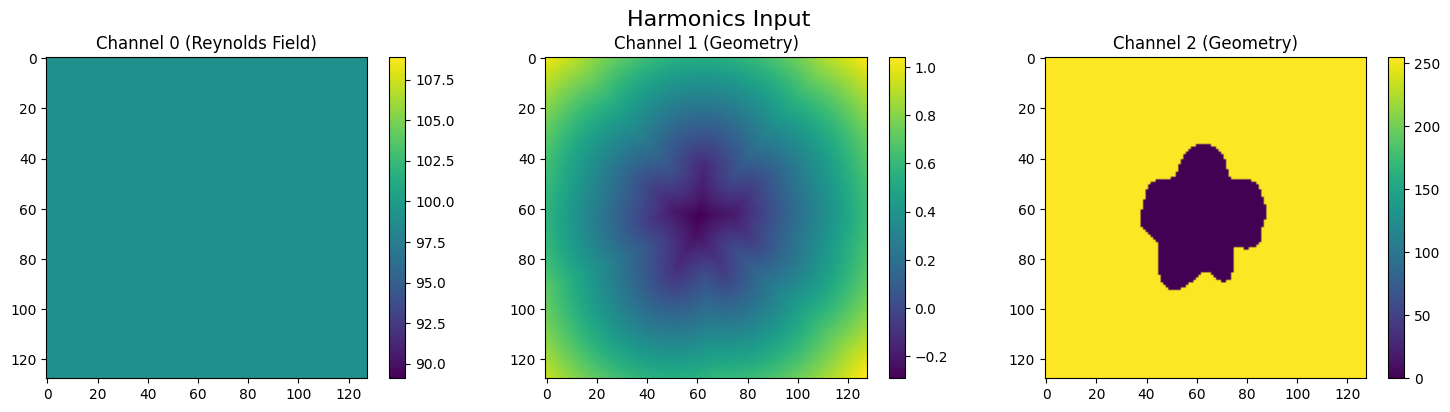

In [ ]:
def visualize_X(X, sample_idx=0, title="Input Sample"):

    sample = X[sample_idx]
    c0 = sample[0]
    c1 = sample[1]
    c2 = sample[2]

    fig, axs = plt.subplots(1, 3, figsize=(15,4))

    im0 = axs[0].imshow(c0)
    axs[0].set_title("Channel 0 (Reynolds Field)")
    plt.colorbar(im0, ax=axs[0])

    im1 = axs[1].imshow(c1)
    axs[1].set_title("Channel 1 (Geometry)")
    plt.colorbar(im1, ax=axs[1])

    im2 = axs[2].imshow(c2)
    axs[2].set_title("Channel 2 (Geometry)")
    plt.colorbar(im2, ax=axs[2])

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

visualize_X(harm_X, sample_idx=0, title="Harmonics Input")

### Checking channel 2 is Binary or not

In [ ]:
np.unique(harm_X[0,2])

array([  0., 255.])

### Checking channel 2 is SDF or not:
SDF properties:

Zero ≈ boundary

Positive inside one region

Negative inside the other

Magnitude = distance from boundary

In [ ]:
print("Min:", harm_X[0,1].min())
print("Max:", harm_X[0,1].max())

Min: -0.2914289352310936
Max: 1.0416384906394713


## So, the three input channels are:
1. Re field → tells flow strength
2. SDF → smooth geometry description
3. Mask → hard geometry description

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_Y(Y, sample_idx=0, title="Output Sample"):

    sample = Y[sample_idx]

    u = sample[0]
    v = sample[1]
    p = sample[2]
    ch3 = sample[3]

    vel_mag = np.sqrt(u**2 + v**2)

    fig, axs = plt.subplots(2,3, figsize=(15,8))

    im0 = axs[0,0].imshow(u)
    axs[0,0].set_title("Channel 0: u velocity")
    plt.colorbar(im0, ax=axs[0,0])

    im1 = axs[0,1].imshow(v)
    axs[0,1].set_title("Channel 1: v velocity")
    plt.colorbar(im1, ax=axs[0,1])

    im2 = axs[0,2].imshow(p)
    axs[0,2].set_title("Channel 2: Pressure")
    plt.colorbar(im2, ax=axs[0,2])

    im3 = axs[1,0].imshow(vel_mag)
    axs[1,0].set_title("Velocity Magnitude")
    plt.colorbar(im3, ax=axs[1,0])

    im4 = axs[1,1].imshow(ch3)
    axs[1,1].set_title("Channel 3")
    plt.colorbar(im4, ax=axs[1,1])

    axs[1,2].axis("off")

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

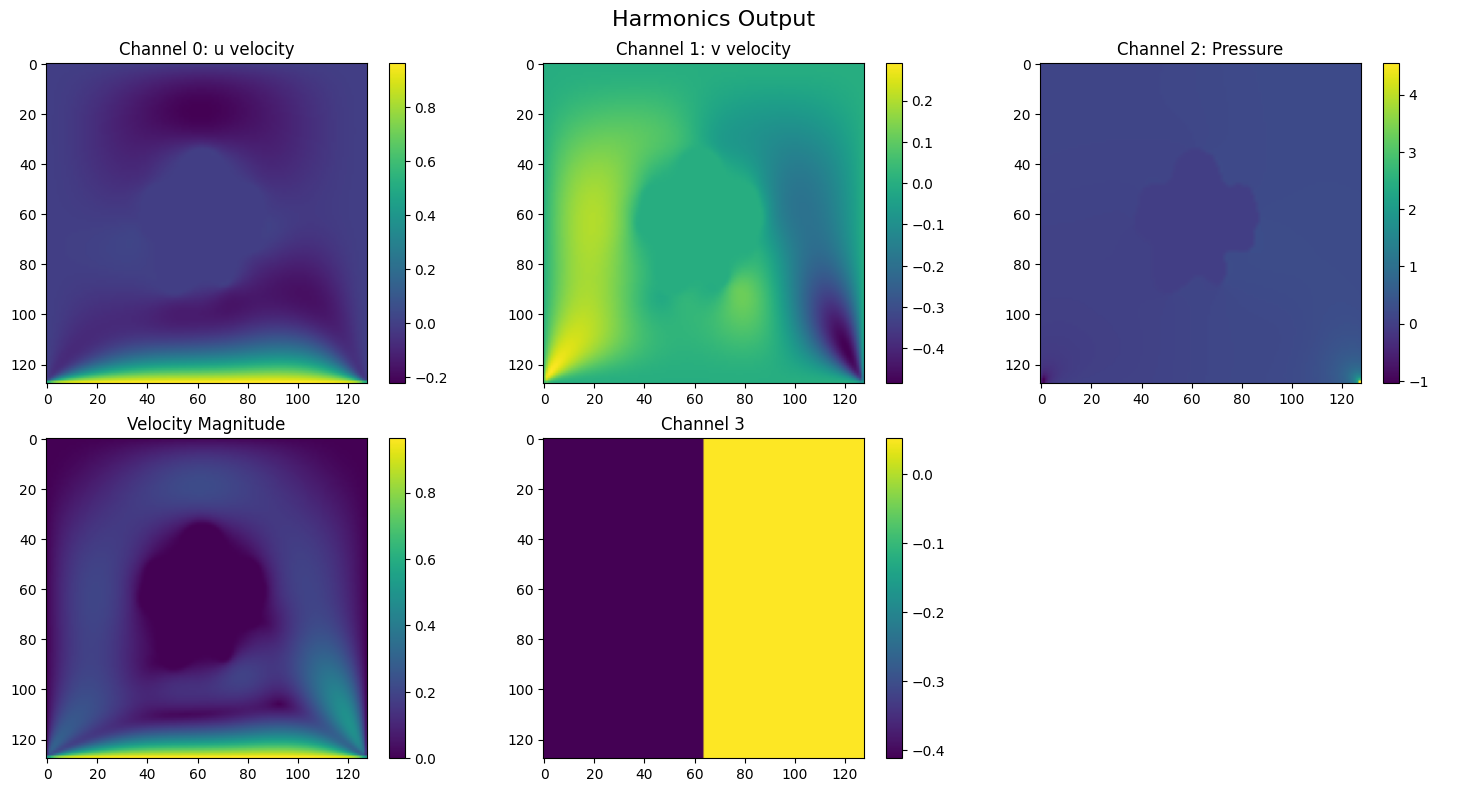

In [ ]:
visualize_Y(harm_Y, sample_idx=0, title="Harmonics Output")

So, Y_harm :     
- [0] u velocity
- [1] v velocity
- [2] pressure
- [3] Fixed auxiliary domain field (not physical output)

In [ ]:
nurbs_X = np.load("/content/drive/MyDrive/128x128/nurbs_lid_driven_cavity_X.npz")["data"]
nurbs_Y = np.load("/content/drive/MyDrive/128x128/nurbs_lid_driven_cavity_Y.npz")["data"]

skeleton_X = np.load("/content/drive/MyDrive/128x128/skelneton_lid_driven_cavity_X.npz")["data"]
skeleton_Y = np.load("/content/drive/MyDrive/128x128/skelneton_lid_driven_cavity_Y.npz")["data"]

print("NURBS X:", nurbs_X.shape)
print("NURBS Y:", nurbs_Y.shape)

print("Skeleton X:", skeleton_X.shape)
print("Skeleton Y:", skeleton_Y.shape)

NURBS X: (1000, 3, 128, 128)
NURBS Y: (1000, 4, 128, 128)
Skeleton X: (1000, 3, 128, 128)
Skeleton Y: (1000, 4, 128, 128)


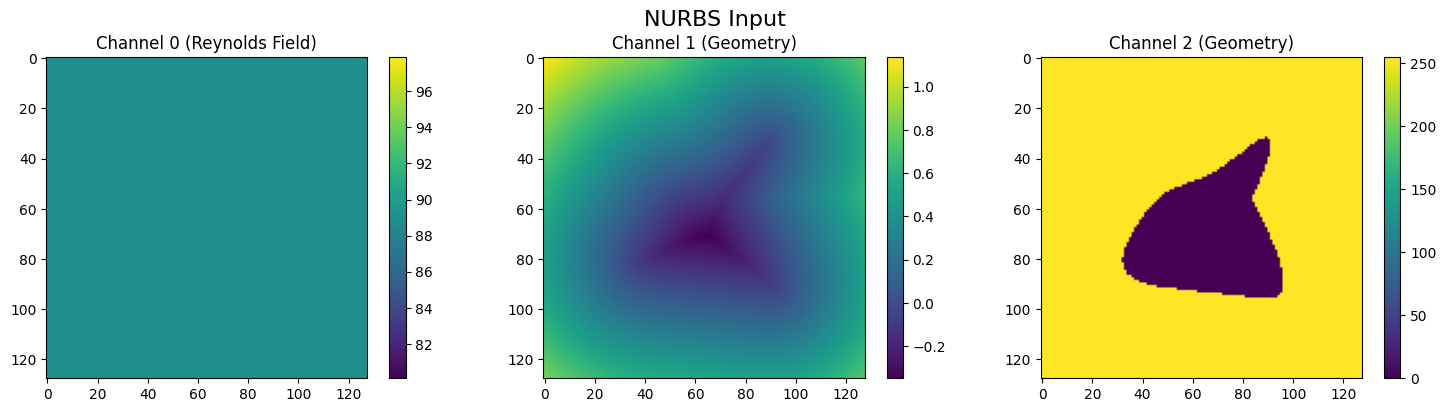

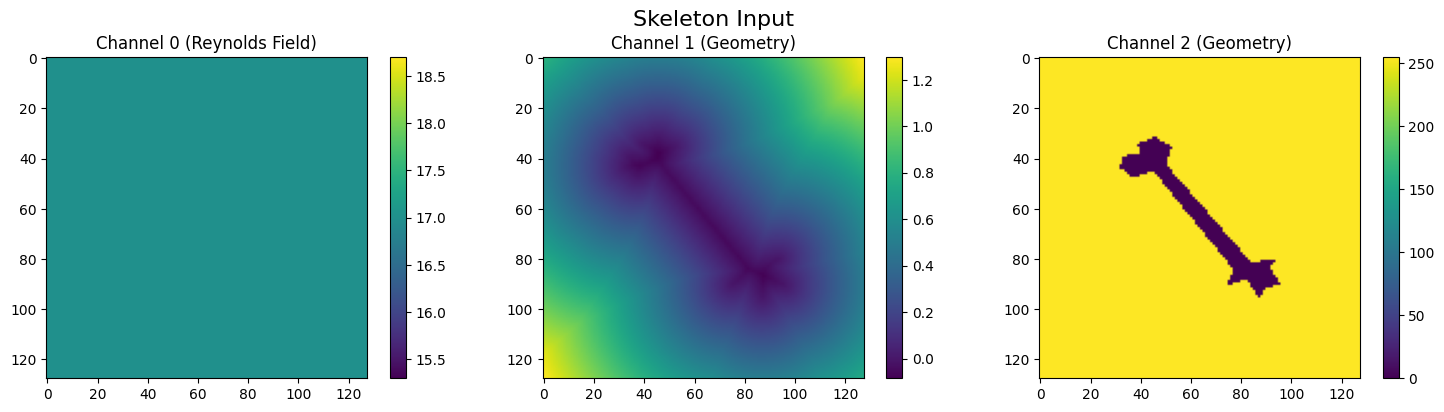

In [ ]:
visualize_X(nurbs_X, sample_idx=0, title="NURBS Input")
visualize_X(skeleton_X, sample_idx=0, title="Skeleton Input")

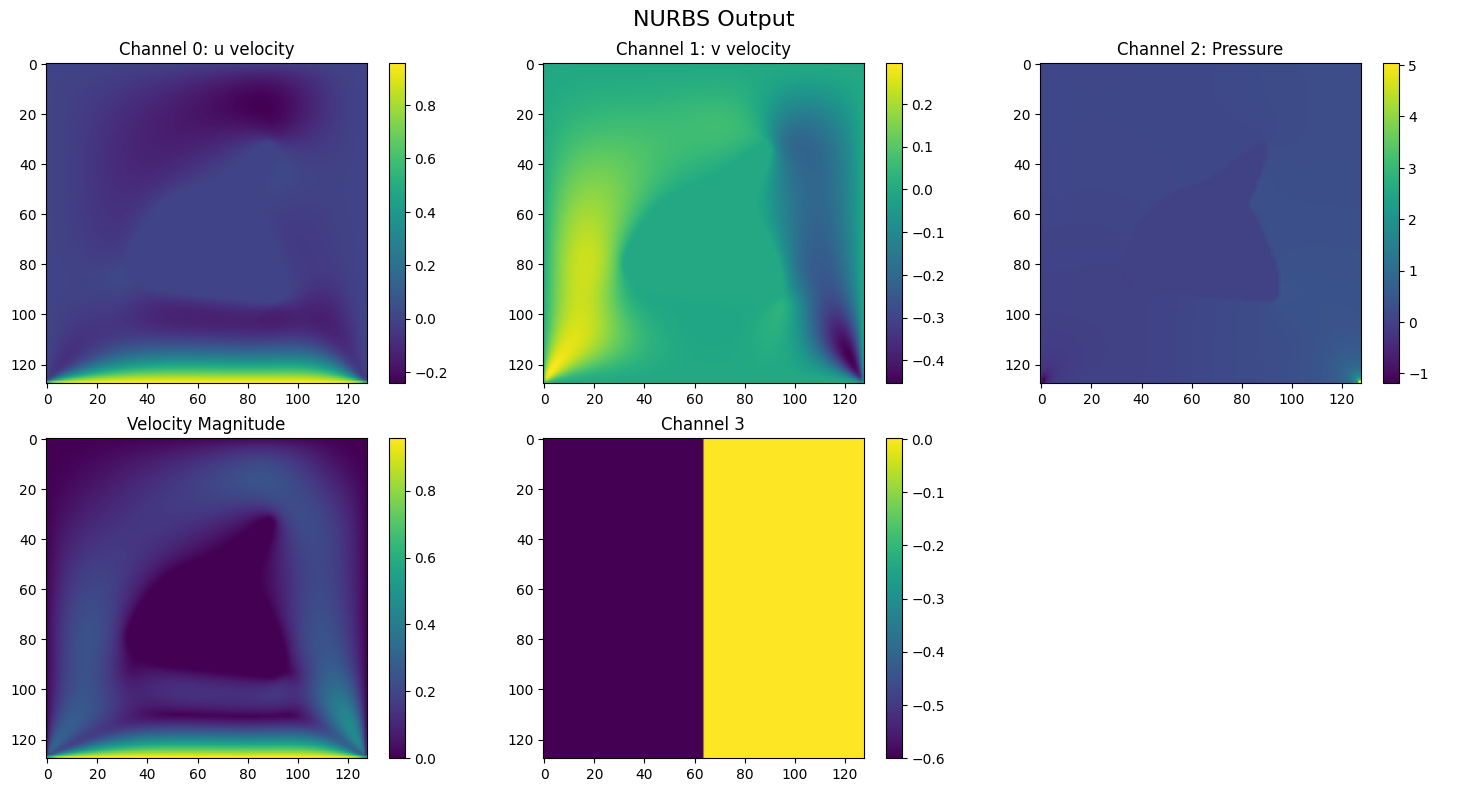

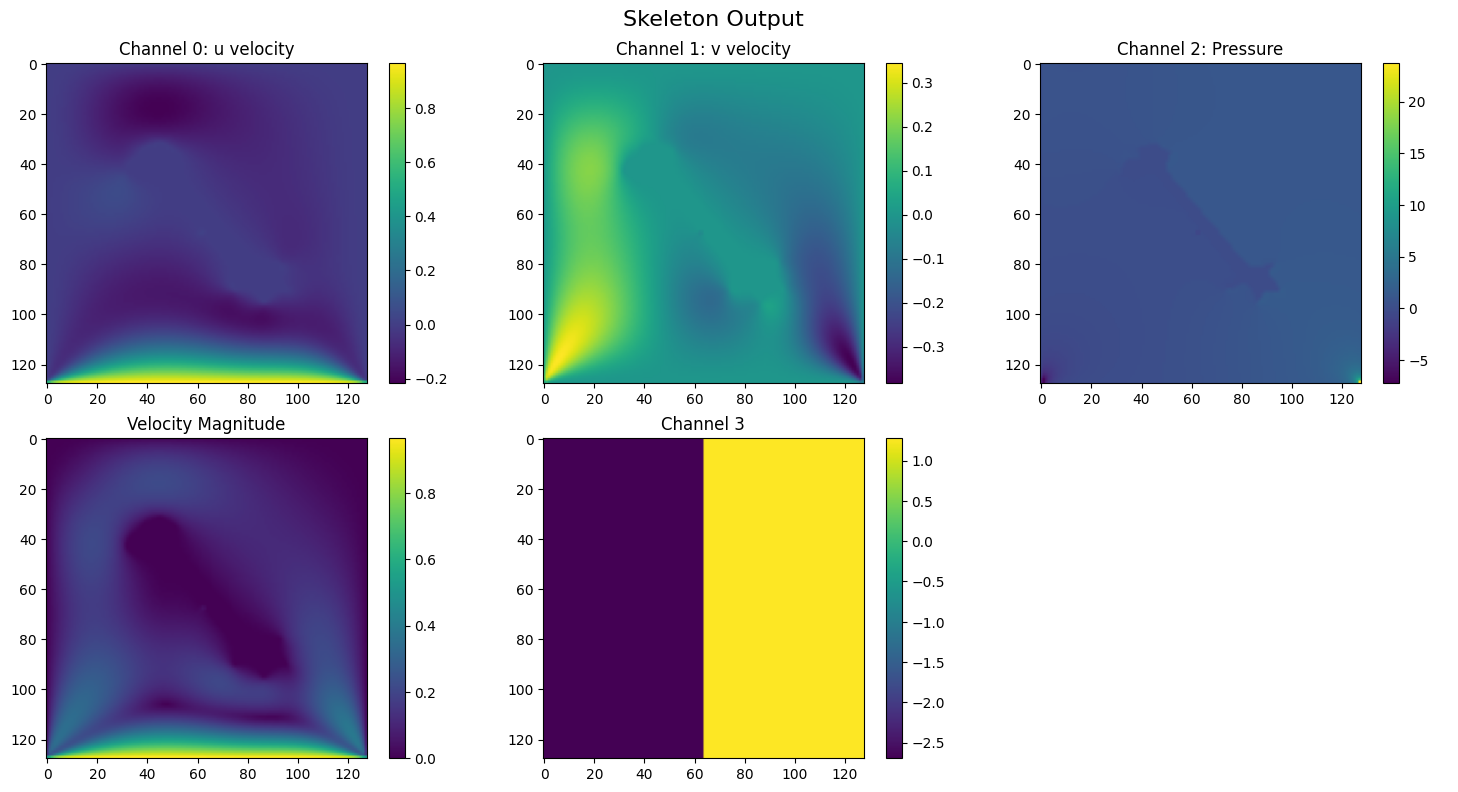

In [ ]:
visualize_Y(nurbs_Y, sample_idx=0, title="NURBS Output")
visualize_Y(skeleton_Y, sample_idx=0, title="Skeleton Output")

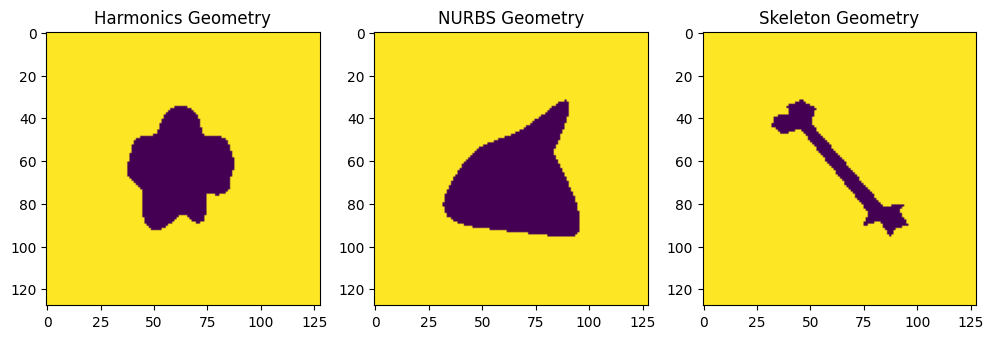

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(harm_X[0,2])
plt.title("Harmonics Geometry")

plt.subplot(1,3,2)
plt.imshow(nurbs_X[0,2])
plt.title("NURBS Geometry")

plt.subplot(1,3,3)
plt.imshow(skeleton_X[0,2])
plt.title("Skeleton Geometry")

plt.show()

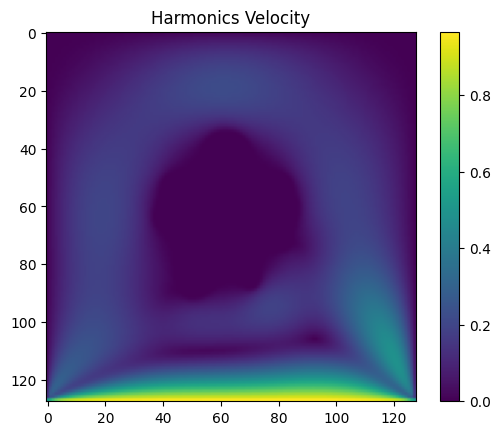

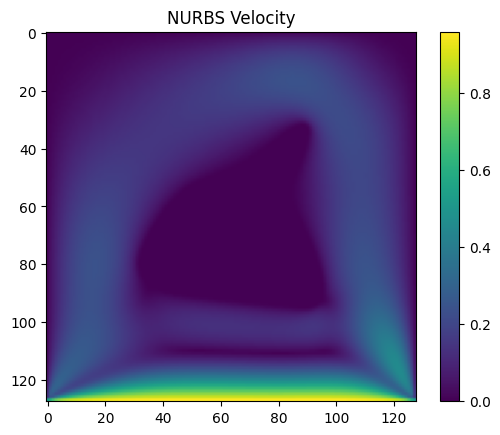

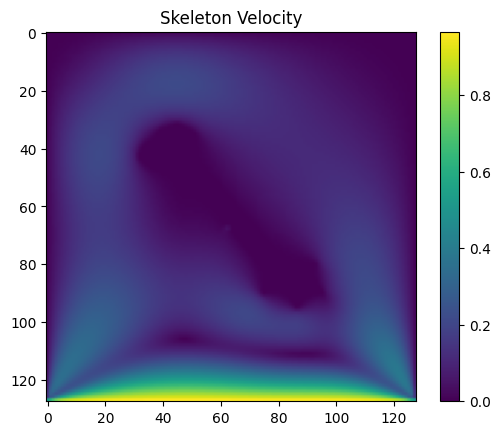

In [ ]:
def plot_velocity_mag(Y, title):
    u = Y[0,0]
    v = Y[0,1]
    vel = np.sqrt(u**2 + v**2)

    plt.imshow(vel)
    plt.colorbar()
    plt.title(title)
    plt.show()

plot_velocity_mag(harm_Y, "Harmonics Velocity")
plot_velocity_mag(nurbs_Y, "NURBS Velocity")
plot_velocity_mag(skeleton_Y, "Skeleton Velocity")